# Assignment 2 - Question 1: Exact Line Search

This notebook answers Question 1(a)–(c). It implements steepest descent with exact line search for the quadratic objective

$$J(w)=\frac{1}{2}w^TAw+b^Tw,$$

using NumPy for the calculations and Matplotlib for the optimization-path figure. The optimizer is implemented directly; no optimization library is used.

## Setup

Run the cells from top to bottom in Google Colab. NumPy and Matplotlib are available in the standard Colab Python runtime.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Arc

np.set_printoptions(precision=10, suppress=True)

## (a) Implement exact line search

The gradient is $\nabla J(w_t)=Aw_t+b$. The negative-gradient direction and exact step size are

$$g_t=-(Aw_t+b), \qquad \alpha_t=\frac{g_t^Tg_t}{g_t^TAg_t},$$

followed by $w_{t+1}=w_t+\alpha_tg_t$. Stop when $\|Aw_t+b\|_2<10^{-10}$ or when the maximum number of steps is reached. The returned list contains independent copies of the initial point and each generated point.

In [4]:
def exact_line_search_quadratic(A, b, w0, num_steps):
    """Minimize 0.5 * w.T @ A @ w + b.T @ w by exact line search."""
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    w = np.asarray(w0, dtype=float).copy()

    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError("A must be a non-empty square matrix.")
    if b.shape != (A.shape[0],) or w.shape != (A.shape[0],):
        raise ValueError("b and w0 must be vectors with length matching A.")
    if not np.all(np.isfinite(A)) or not np.all(np.isfinite(b)) or not np.all(np.isfinite(w)):
        raise ValueError("A, b, and w0 must contain only finite values.")
    if not np.allclose(A, A.T):
        raise ValueError("A must be symmetric.")
    if isinstance(num_steps, (bool, np.bool_)) or not isinstance(num_steps, (int, np.integer)) or num_steps < 0:
        raise ValueError("num_steps must be a non-negative integer.")

    try:
        np.linalg.cholesky(A)
    except np.linalg.LinAlgError as exc:
        raise ValueError("A must be positive definite.") from exc

    iterates = [w.copy()]
    tolerance = 1e-10

    for _ in range(num_steps):
        gradient = A @ w + b
        if np.linalg.norm(gradient, ord=2) < tolerance:
            break

        direction = -gradient
        denominator = float(direction @ A @ direction)
        if not np.isfinite(denominator) or denominator <= 0.0:
            raise FloatingPointError(
                "The exact line-search denominator is not positive and finite."
            )

        step_size = float(direction @ direction) / denominator
        next_w = w + step_size * direction
        if not np.all(np.isfinite(next_w)):
            raise FloatingPointError("The update produced a non-finite iterate.")

        w = next_w
        iterates.append(w.copy())

    return iterates

## (b) Run the specified example

The assignment data are $A=\begin{bmatrix}2&0\\0&8\end{bmatrix}$, $b=[0,0]^T$, and $w_0=[2,1]^T$, giving $J(w_1,w_2)=w_1^2+4w_2^2$. The minimizer is $w^*=(0,0)$.

In [5]:
A = np.array([[2.0, 0.0], [0.0, 8.0]])
b = np.array([0.0, 0.0])
w0 = np.array([2.0, 1.0])
num_steps = 10

def objective(w):
    return 0.5 * w @ A @ w + b @ w

iterates = exact_line_search_quadratic(A, b, w0, num_steps)
print(f"Returned {len(iterates)} points (including the initial point):")
for t, w_t in enumerate(iterates):
    print(f"w_{t} = {w_t}")

print("\nObjective values:")
for t, w_t in enumerate(iterates):
    print(f"J(w_{t}) = {objective(w_t):.12g}")

Returned 11 points (including the initial point):
w_0 = [2. 1.]
w_1 = [ 1.4117647059 -0.1764705882]
w_2 = [0.5294117647 0.2647058824]
w_3 = [ 0.3737024221 -0.0467128028]
w_4 = [0.1401384083 0.0700692042]
w_5 = [ 0.0989212294 -0.0123651537]
w_6 = [0.037095461  0.0185477305]
w_7 = [ 0.0261850313 -0.0032731289]
w_8 = [0.0098193867 0.0049096934]
w_9 = [ 0.0069313318 -0.0008664165]
w_10 = [0.0025992494 0.0012996247]

Objective values:
J(w_0) = 8
J(w_1) = 2.11764705882
J(w_2) = 0.560553633218
J(w_3) = 0.148381844087
J(w_4) = 0.0392775469642
J(w_5) = 0.0103969977258
J(w_6) = 0.00275214645684
J(w_7) = 0.000728509356221
J(w_8) = 0.000192840711941
J(w_9) = 5.10460708079e-05
J(w_10) = 1.35121952139e-05


### Consecutive-gradient dot products

For exact line search, $g_t^Tg_{t+1}$ should be zero in exact arithmetic. The check below uses the absolute tolerance $10^{-10}$ and only evaluates indices for which both gradients are available.

In [6]:
gradients = [-(A @ w_t + b) for w_t in iterates]
dot_tolerance = 1e-10

print(f"Approximate-zero criterion: |g_t.T @ g_(t+1)| <= {dot_tolerance:g}\n")
for t in range(min(5, len(gradients) - 1)):
    dot_product = float(gradients[t] @ gradients[t + 1])
    approximately_zero = abs(dot_product) <= dot_tolerance
    print(
        f"t={t}: g_{t}.T @ g_{t + 1} = {dot_product:.12g}; "
        f"approximately zero: {approximately_zero}"
    )

Approximate-zero criterion: |g_t.T @ g_(t+1)| <= 1e-10

t=0: g_0.T @ g_1 = -3.5527136788e-15; approximately zero: True
t=1: g_1.T @ g_2 = 0; approximately zero: True
t=2: g_2.T @ g_3 = 1.44328993201e-15; approximately zero: True
t=3: g_3.T @ g_4 = 1.11022302463e-16; approximately zero: True
t=4: g_4.T @ g_5 = -1.38777878078e-17; approximately zero: True


## (c) Plot the optimization path

The contour plot shows $J(w_1,w_2)=w_1^2+4w_2^2$. Each consecutive pair of iterates is joined by a line segment. At each intermediate iterate, a small arc marks the angle between the rays toward the previous and next iterates; the exact-line-search path is expected to turn by approximately $90^\circ$ there. These are path-turn angles, not contour tangencies.

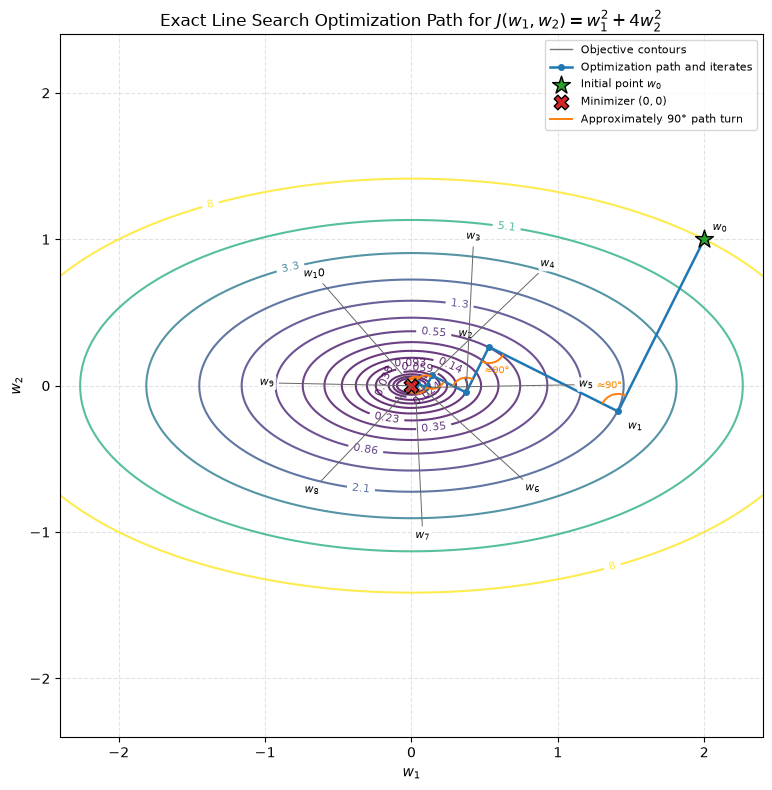

In [7]:
path = np.asarray(iterates)
grid_extent = 2.4
grid_values = np.linspace(-grid_extent, grid_extent, 300)
W1, W2 = np.meshgrid(grid_values, grid_values)
J_grid = W1**2 + 4.0 * W2**2
positive_levels = np.geomspace(0.01, 8.0, 16)

fig, ax = plt.subplots(figsize=(9, 8))
contours = ax.contour(W1, W2, J_grid, levels=positive_levels, cmap="viridis", alpha=0.8)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.2g")

path_line, = ax.plot(
    path[:, 0], path[:, 1], "-o", color="tab:blue", linewidth=1.8,
    markersize=4, label="Optimization path and iterates", zorder=3
)
ax.scatter(*path[0], marker="*", s=180, color="tab:green", edgecolor="black",
           label="Initial point $w_0$", zorder=5)
ax.scatter(0.0, 0.0, marker="X", s=110, color="tab:red", edgecolor="black",
           label="Minimizer $(0,0)$", zorder=6)

label_offsets = [(6, 6), (7, -13), (-22, 7), (0, 110), (78, 78),
                 (110, 0), (78, -78), (0, -110), (-78, -78),
                 (-110, 0), (-78, 78)]
for t, point in enumerate(path):
    annotation_options = {}
    if t >= 3:
        annotation_options = {
            "arrowprops": {"arrowstyle": "-", "color": "0.4", "linewidth": 0.7},
            "bbox": {"boxstyle": "round,pad=0.15", "facecolor": "white",
                     "edgecolor": "none", "alpha": 0.9},
        }
    ax.annotate(f"$w_{t}$", point, xytext=label_offsets[t],
                textcoords="offset points", fontsize=8, zorder=7,
                **annotation_options)

angle_label_added = False
for t in range(1, len(path) - 1):
    ray_to_previous = path[t - 1] - path[t]
    ray_to_next = path[t + 1] - path[t]
    angle_previous = np.degrees(np.arctan2(ray_to_previous[1], ray_to_previous[0]))
    angle_next = np.degrees(np.arctan2(ray_to_next[1], ray_to_next[0]))
    angle_span = (angle_next - angle_previous) % 360.0
    if angle_span > 180.0:
        angle_previous, angle_next = angle_next, angle_previous
        angle_span = 360.0 - angle_span

    radius = 0.12 - 0.075 * (t - 1) / max(1, len(path) - 3)
    arc = Arc(path[t], 2 * radius, 2 * radius, angle=0,
              theta1=angle_previous, theta2=angle_previous + angle_span,
              color="tab:orange", linewidth=1.4, zorder=4)
    ax.add_patch(arc)

    if t <= 2:
        middle_angle = np.radians(angle_previous + angle_span / 2.0)
        label_point = path[t] + 1.55 * radius * np.array(
            [np.cos(middle_angle), np.sin(middle_angle)]
        )
        ax.text(*label_point, "≈90°", color="darkorange", fontsize=7,
                ha="center", va="center", zorder=8)

    if not angle_label_added:
        angle_handle = Line2D([], [], color="tab:orange", linewidth=1.4,
                              label="Approximately 90° path turn")
        angle_label_added = True

contour_handle = Line2D([], [], color="0.45", linewidth=1.0,
                        label="Objective contours")
handles, labels = ax.get_legend_handles_labels()
handles.insert(0, contour_handle)
labels.insert(0, "Objective contours")
if angle_label_added:
    handles.append(angle_handle)
    labels.append("Approximately 90° path turn")
ax.legend(handles=handles, labels=labels, loc="upper right", fontsize=8)
ax.set_xlabel("$w_1$")
ax.set_ylabel("$w_2$")
ax.set_title("Exact Line Search Optimization Path for $J(w_1,w_2)=w_1^2+4w_2^2$")
ax.set_xlim(-grid_extent, grid_extent)
ax.set_ylim(-grid_extent, grid_extent)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()